# Introduction
## Project Overview

In this project we analyze data from ecommerce platform.  
The dataset contains millions of orders placed by thousands of customers.  

- User can place multiple orders
- Order contains multiple products  
- Products belong to aisles and departments

The objective of projetc is to tranform raw data into actionable business insights and predictive models that support smarter business decision.

## Business Questions

- Which products are reordered most frequently, and which are purchased the least? +

- Which aisles and departments contribute the largest number of orders? +

- When do customers usually place orders (day and hour)?

- Which aisles are frequently purchased together?

- After how many days without an order can we consider a customer at risk of churning?

- Do customers fill their baskets more on weekends or during the week?

- At how many items in a basket does a customer tend to stop adding products?

- Is there any relationship between the last order and the reorder?

- In how many days will this customer place their next order?

- Which products are most often added to the shopping cart first?

- Which products are most often added to the shopping cart together?

- Can we predict the reorder of a product by a specific buyer?

- Can we predict a buyer's shopping cart based on their past purchases?

- Can we predict the number of items in a customer's next basket?

## Loading, editing, and merging datasets

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.model_selection import train_test_split
import lightgbm as lgb
from sklearn.metrics import accuracy_score, roc_auc_score

aisles = pd.read_csv("datasets/aisles.csv")
departments = pd.read_csv("datasets/departments.csv")
order_products = pd.read_csv("datasets/order_products.csv")
orders = pd.read_csv("datasets/orders.csv")
products = pd.read_csv("datasets/products.csv")

print("orders:", orders.shape)
print("order_products:", order_products.shape)
print("products:", products.shape)
print("aisles:", aisles.shape)
print("departments:", departments.shape)


orders: (1444444, 6)
order_products: (13692886, 4)
products: (49688, 4)
aisles: (134, 2)
departments: (21, 2)


In [43]:
orders["order_id"].nunique()

1444444

In [44]:
order_products["order_id"].nunique()

1357541

In [45]:
df = orders.merge(order_products, on="order_id", how="inner")
print("after first merge:", df.shape)

after first merge: (13692886, 9)


In [46]:
df = df.merge(products, on="product_id", how="left")
print("after products:", df.shape)

after products: (13692886, 12)


In [47]:
df=df.merge(aisles, on="aisle_id", how="left")
print("after aisles:", df.shape)

after aisles: (13692886, 13)


In [48]:
df=df.merge(departments, on="department_id", how="left")
print("after department:", df.shape)

after department: (13692886, 14)


In [49]:
df.isnull().sum().sort_values(ascending=False)

days_since_prior_order    878993
aisle                        449
aisle_id                     449
product_name                 449
reordered                    449
product_id                   449
department                   449
department_id                449
add_to_cart_order            446
user_id                      357
order_number                 244
order_dow                    203
order_hour_of_day            198
order_id                       0
dtype: int64

In [50]:
df["days_since_prior_order"] = df["days_since_prior_order"].fillna(df["days_since_prior_order"].median())
df.isnull().sum().sort_values(ascending=False)

department_id             449
aisle                     449
aisle_id                  449
product_name              449
reordered                 449
product_id                449
department                449
add_to_cart_order         446
user_id                   357
order_number              244
order_dow                 203
order_hour_of_day         198
days_since_prior_order      0
order_id                    0
dtype: int64

In [51]:
df.duplicated().sum()
df.isnull().sum().sort_values(ascending=False)

department_id             449
aisle                     449
aisle_id                  449
product_name              449
reordered                 449
product_id                449
department                449
add_to_cart_order         446
user_id                   357
order_number              244
order_dow                 203
order_hour_of_day         198
days_since_prior_order      0
order_id                    0
dtype: int64

In [52]:
df = df.dropna(subset="product_id")
df.isnull().sum().sort_values(ascending=False)

reordered                 449
add_to_cart_order         446
user_id                   357
order_number              244
order_dow                 203
order_hour_of_day         198
days_since_prior_order      0
order_id                    0
product_id                  0
product_name                0
aisle_id                    0
department_id               0
aisle                       0
department                  0
dtype: int64

In [53]:
df["order_hour_of_day"] = df["order_hour_of_day"].fillna(df["order_hour_of_day"].median())
df.isnull().sum().sort_values(ascending=False)

reordered                 449
add_to_cart_order         446
user_id                   357
order_number              244
order_dow                 203
order_id                    0
days_since_prior_order      0
order_hour_of_day           0
product_id                  0
product_name                0
aisle_id                    0
department_id               0
aisle                       0
department                  0
dtype: int64

In [54]:
df = df.dropna()
df.isnull().sum().sort_values(ascending=False)
df.dtypes

order_id                    int64
user_id                   float64
order_number              float64
order_dow                 float64
order_hour_of_day         float64
days_since_prior_order    float64
product_id                float64
add_to_cart_order         float64
reordered                 float64
product_name               object
aisle_id                  float64
department_id             float64
aisle                      object
department                 object
dtype: object

In [55]:
df.dtypes

order_id                    int64
user_id                   float64
order_number              float64
order_dow                 float64
order_hour_of_day         float64
days_since_prior_order    float64
product_id                float64
add_to_cart_order         float64
reordered                 float64
product_name               object
aisle_id                  float64
department_id             float64
aisle                      object
department                 object
dtype: object

In [56]:
df.to_csv('datasets/cleaned_dataset.csv', index=False)

### Data Cleaning
- Missing 'days_since_prior_order' values were filled with the median.  
- Rows with missing product information were removed.  
- Missing 'order_hour_of_day' values were filled using the median hour.  

This ensures that the dataset remains consistent for analysis and modeling.

Which products are reordered most frequently, and which are purchased the least?

In [57]:
# Aggregate product-level statistics
product_stats = (
    df.groupby(["product_id", "product_name"])
      .agg(
          total_purchases=("order_id", "count"),
          total_reorders=("reordered", "sum")
      )
      .reset_index()
)

# Compute reorder rate
product_stats["reorder_rate"] = (
    product_stats["total_reorders"] /
    product_stats["total_purchases"]
)

product_stats.head()

,product_id,product_name,total_purchases,total_reorders,reorder_rate
0,1.0,Chocolate Sandwich Cookies,773,485.0,0.627426
1,2.0,All-Seasons Salt,37,7.0,0.189189
2,3.0,Robust Golden Unsweetened Oolong Tea,94,66.0,0.702128
3,4.0,Smart Ones Classic Favorites Mini Rigatoni Wit...,149,66.0,0.442953
4,5.0,Green Chile Anytime Sauce,6,2.0,0.333333


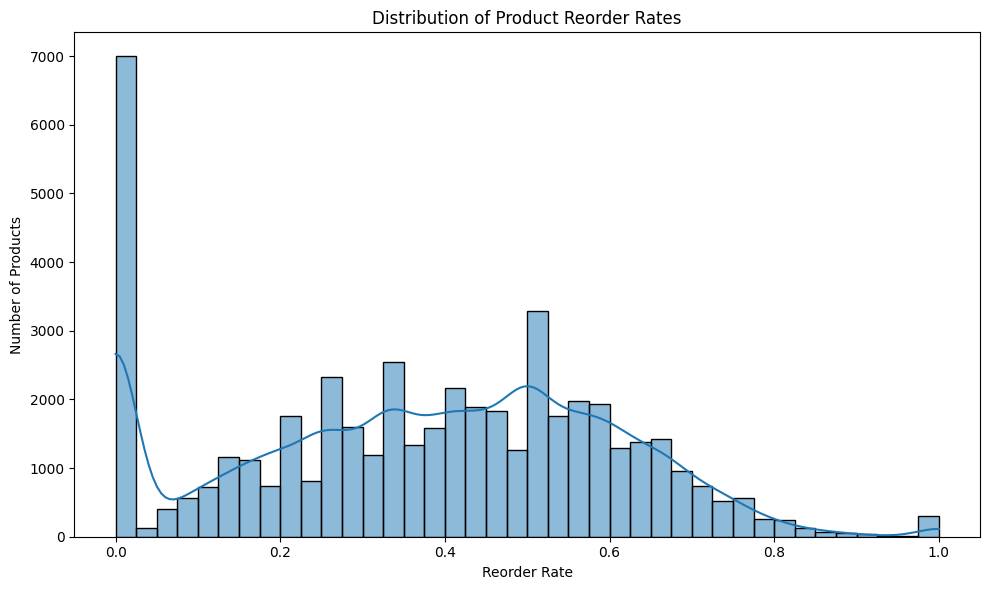

In [58]:
plt.figure(figsize=(10,6))

sns.histplot(
    product_stats["reorder_rate"],
    bins=40,
    kde=True
)

plt.title("Distribution of Product Reorder Rates")
plt.xlabel("Reorder Rate")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()

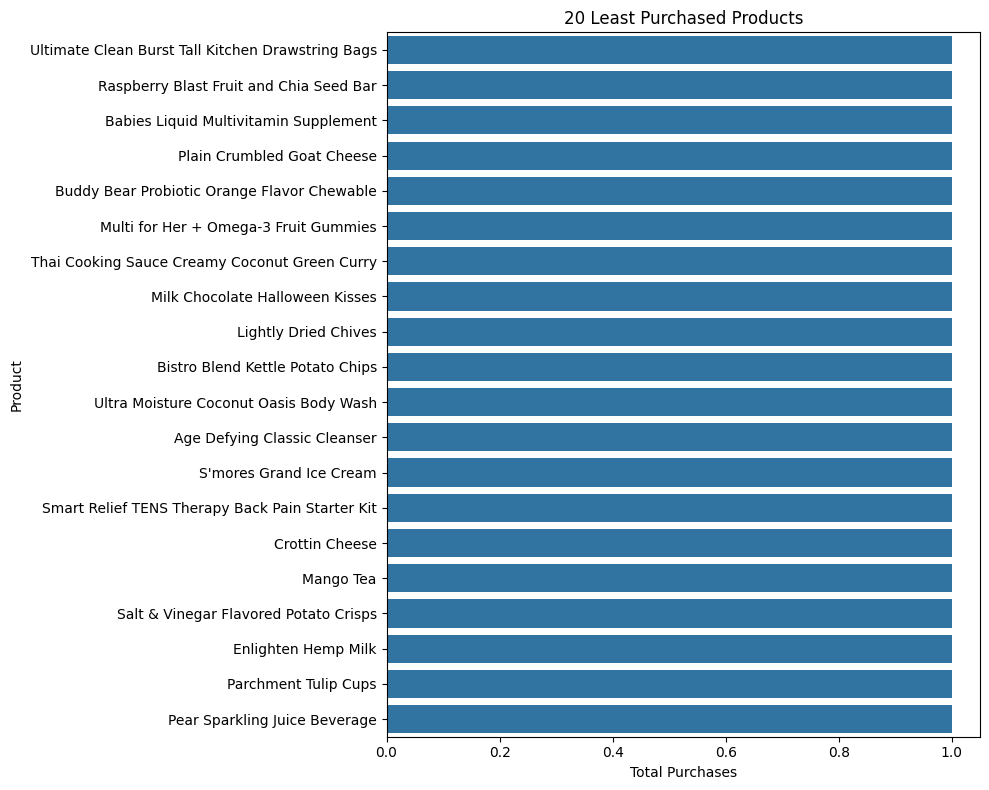

In [59]:
least_purchased = (
    product_stats.sort_values("total_purchases")
                 .head(20)
)

plt.figure(figsize=(10,8))

sns.barplot(
    data=least_purchased,
    y="product_name",
    x="total_purchases"
)

plt.title("20 Least Purchased Products")
plt.xlabel("Total Purchases")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

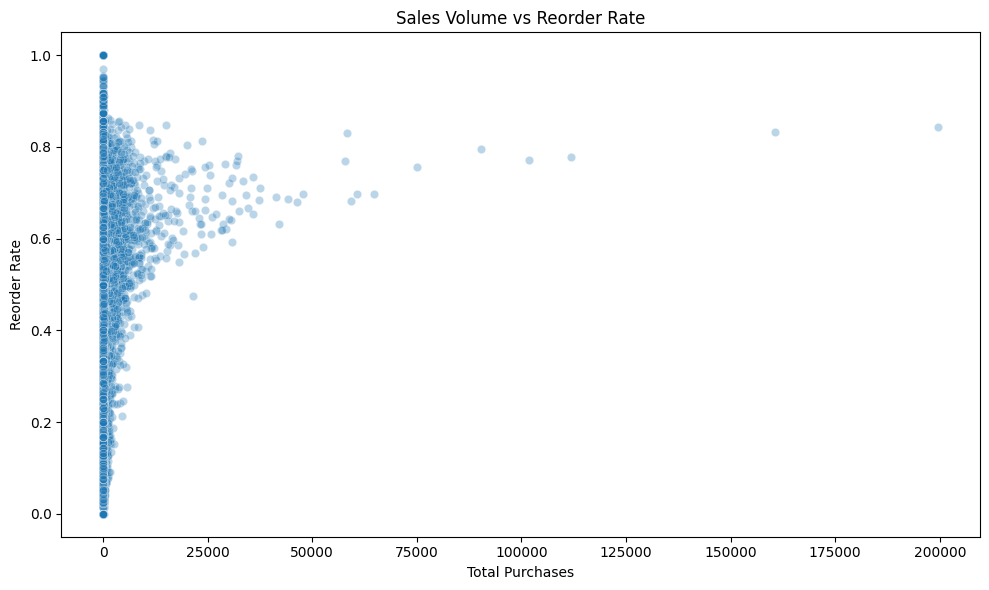

In [60]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=product_stats,
    x="total_purchases",
    y="reorder_rate",
    alpha=0.3
)

plt.title("Sales Volume vs Reorder Rate")
plt.xlabel("Total Purchases")
plt.ylabel("Reorder Rate")
plt.tight_layout()
plt.show()

---
### Which aisles and departments contribute the largest number of orders?
In this section, we aim to identify which product aisles and departments generate the highest number of orders.  
To answer this question, we will use the merged dataset and group the data by aisle and department. Then, we will count the number of products ordered in each category.  
This analysis will help us understand which categories drive the majority of customer purchases and contribute the most to overall sales activity.

In [61]:
df = pd.read_csv("datasets/cleaned_dataset.csv")
top_aisles = df.groupby("aisle")["order_id"].nunique().sort_values(ascending=False).head(15)
top_aisles

aisle
fresh fruits                     756861
fresh vegetables                 603368
packaged vegetables fruits       497821
yogurt                           357865
milk                             331529
packaged cheese                  312119
water seltzer sparkling water    258900
soy lactosefree                  230036
chips pretzels                   226746
bread                            222050
eggs                             185792
refrigerated                     181499
frozen produce                   167087
crackers                         155311
ice cream ice                    149047
Name: order_id, dtype: int64

In [62]:
top_departments = df.groupby("department")["order_id"].nunique().sort_values(ascending=False).head(15)
top_departments

department
produce            1017822
dairy eggs          919559
beverages           615400
snacks              586575
frozen              498703
pantry              471690
bakery              372030
deli                325104
canned goods        287840
dry goods pasta     252148
meat seafood        242568
breakfast           221300
household           198133
personal care       134232
international        93110
Name: order_id, dtype: int64

In [63]:
fig = px.bar(
    top_aisles.reset_index(),
    x="aisle",
    y="order_id",
    title="Top 10 Aisles by Number of Orders"
)

fig.show()

In [64]:
fig = px.bar(
    top_departments.reset_index(),
    x="department",
    y="order_id",
    title="Top 10 Departments by Number of Orders"
)


fig.show()

---
### When do customers usually place orders (day and hour)?


In [65]:
orders_time = (df.groupby(["order_dow","order_hour_of_day"])["order_id"].nunique().reset_index(name="orders"))
pivot_orders = orders_time.pivot(index="order_dow", columns = "order_hour_of_day", values = "orders")

day_labels = ["Sunday", "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday"]

pivot_orders.index = day_labels

fig = px.imshow (
    pivot_orders,
    color_continuous_scale = "YlOrRd",
    aspect ="auto",
    labels = dict(x="Hour of Day", y="Day of Week", color="Number of Orders"),
    title = "When do customers usually place orders?"
)

fig.update_layout(xaxis_title="Hour of Day", yaxis_title = "Day of Week (0=Sunday)")

fig.show()


Which aisles are frequently purchased together?

In [66]:
# Create aisle presence matrix per order
order_aisle_matrix = pd.crosstab(
    df["order_id"],
    df["aisle"]
)

# Convert counts to binary (presence / absence)
order_aisle_matrix = (order_aisle_matrix > 0).astype(int)

order_aisle_matrix.head()

aisle,air fresheners candles,asian foods,baby accessories,baby bath body care,baby food formula,bakery desserts,baking ingredients,baking supplies decor,beauty,beers coolers,...,spreads,tea,tofu meat alternatives,tortillas flat bread,trail mix snack mix,trash bags liners,vitamins supplements,water seltzer sparkling water,white wines,yogurt
order_id,,,,,,,,,,,,,,,,,,,,,
2,0,0,0,0,0,0,1,0,0,0,...,1,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
6,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
20,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


In [67]:
aisle_corr = order_aisle_matrix.corr()

aisle_corr.head()

aisle,air fresheners candles,asian foods,baby accessories,baby bath body care,baby food formula,bakery desserts,baking ingredients,baking supplies decor,beauty,beers coolers,...,spreads,tea,tofu meat alternatives,tortillas flat bread,trail mix snack mix,trash bags liners,vitamins supplements,water seltzer sparkling water,white wines,yogurt
aisle,,,,,,,,,,,,,,,,,,,,,
air fresheners candles,1.000000,0.003866,0.002441,0.006880,-0.005905,0.004539,0.005934,0.007670,0.021904,0.003267,...,0.002466,0.014578,-0.003345,0.003509,0.000709,0.025650,0.013219,0.009504,0.008186,-0.006549
asian foods,0.003866,1.000000,0.004168,0.004060,0.008919,0.002235,0.046725,0.009970,0.003793,-0.000907,...,0.029459,0.021196,0.087811,0.036128,0.000060,0.004949,0.013067,0.006318,-0.002589,0.024760
baby accessories,0.002441,0.004168,1.000000,0.021030,0.043519,0.002100,0.004713,0.002900,0.005246,-0.003431,...,0.007439,0.005033,0.007859,0.007234,-0.001617,0.008132,0.009396,0.008937,-0.002950,0.012067
baby bath body care,0.006880,0.004060,0.021030,1.000000,0.031925,-0.000211,0.006753,0.004312,0.008632,-0.000933,...,0.008997,0.005269,0.002768,0.007655,0.000365,0.009544,0.009024,0.005421,-0.000276,0.012498
baby food formula,-0.005905,0.008919,0.043519,0.031925,1.000000,0.000926,0.010269,0.000340,0.000629,-0.014208,...,0.029544,-0.001357,0.020491,0.028302,0.004224,0.003442,0.010987,0.015802,-0.012177,0.104896


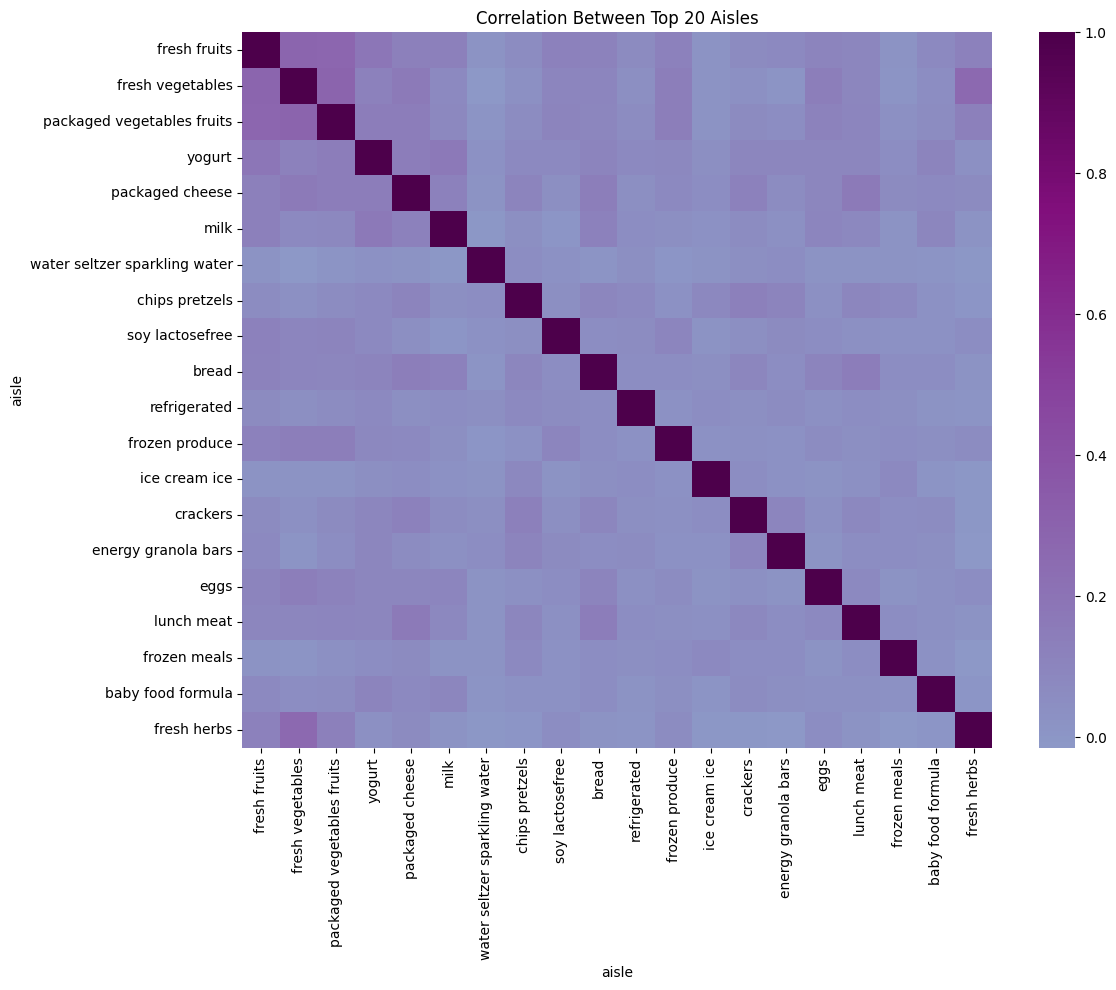

In [78]:
# Select top 20 most frequent aisles
top_aisles = (
    df["aisle"]
      .value_counts()
      .head(20)
      .index
)

corr_subset = aisle_corr.loc[top_aisles, top_aisles]

plt.figure(figsize=(12,10))

sns.heatmap(
    corr_subset,
    cmap="BuPu",
    center=0
)

plt.title("Correlation Between Top 20 Aisles")
plt.tight_layout()
plt.show()

### Can we predict the reorder of a product by a specific buyer?

In [69]:
def init_neural_ia(iteration = 500):
    """
    crée un model d'ia neural network et le renvoie
    """
    model = MLPClassifier(
        hidden_layer_sizes=(100),     # crée les "hiddden layers"
        activation='relu',                # fait en sorte que si les lien des neuronnes sont inferieur a 0 les mettent a 0
        solver='adam',                    # fait en sorte que plus le resultat est proche de la valeur attendue moins il fluctue les modificatio
        max_iter=iteration                # le nombre d'iteration
    )
    return model


def reorder_df(df):
    
    user_col = df.groupby('user_id').agg(
        user_total_orders = ('order_number', 'max'),
        user_moy_basket_size = ('product_id', 'count'),
        user_moy_reorder_days = ('days_since_prior_order', 'mean'),
    ).reset_index()

    # Features par produit
    prod_col = df.groupby('product_id').agg(
        product_total_orders = ('order_id', 'count'),
        product_reorder_rate = ('reordered', 'mean'),
    ).reset_index()

    # Features par paire (user × product)
    fus_col = df.groupby(['user_id', 'product_id']).agg(
        fus_order_count = ('order_id', 'count'),
        fus_avg_cart_position = ('add_to_cart_order', 'mean'),
        fus_reorder_rate = ('reordered', 'mean'),
        fus_last_order = ('order_number', 'max'),
    ).reset_index()

    # Création de la nouvelle df
    df_new = (df[['user_id', 'product_id', 'reordered']]
                .merge(user_col, on='user_id', how='left')
                .merge(prod_col, on='product_id', how='left')
                .merge(fus_col, on=['user_id', 'product_id'], how='left')
                .drop_duplicates(subset=['user_id', 'product_id'])
                .reset_index(drop=True))
    return df_new

In [70]:
df_reord = reorder_df(df)
df_reord

,user_id,product_id,reordered,user_total_orders,user_moy_basket_size,user_moy_reorder_days,product_total_orders,product_reorder_rate,fus_order_count,fus_avg_cart_position,fus_reorder_rate,fus_last_order
0,1.0,196.0,0.0,10.0,44,19.863636,14994,0.778111,7,1.428571,0.857143,10.0
1,1.0,14084.0,0.0,10.0,44,19.863636,6723,0.813922,1,2.000000,0.000000,1.0
2,1.0,12427.0,0.0,10.0,44,19.863636,2633,0.750095,7,3.857143,0.857143,10.0
3,1.0,26088.0,0.0,10.0,44,19.863636,1042,0.532630,2,4.500000,0.500000,2.0
4,1.0,26405.0,0.0,10.0,44,19.863636,512,0.464844,2,5.000000,0.500000,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...
7656665,206209.0,14197.0,1.0,13.0,72,20.875000,4697,0.326591,1,5.000000,1.000000,13.0
7656666,206209.0,38730.0,0.0,13.0,72,20.875000,1263,0.613618,1,6.000000,0.000000,13.0
7656667,206209.0,31477.0,0.0,13.0,72,20.875000,1231,0.627132,1,7.000000,0.000000,13.0
7656668,206209.0,6567.0,0.0,13.0,72,20.875000,606,0.536304,1,8.000000,0.000000,13.0


In [71]:
inputt = df_reord.drop('reordered' , axis=1)
output = df_reord['reordered']

input_train, input_test, output_train, output_test = train_test_split(inputt, output, test_size=0.2, random_state=24, stratify=output)

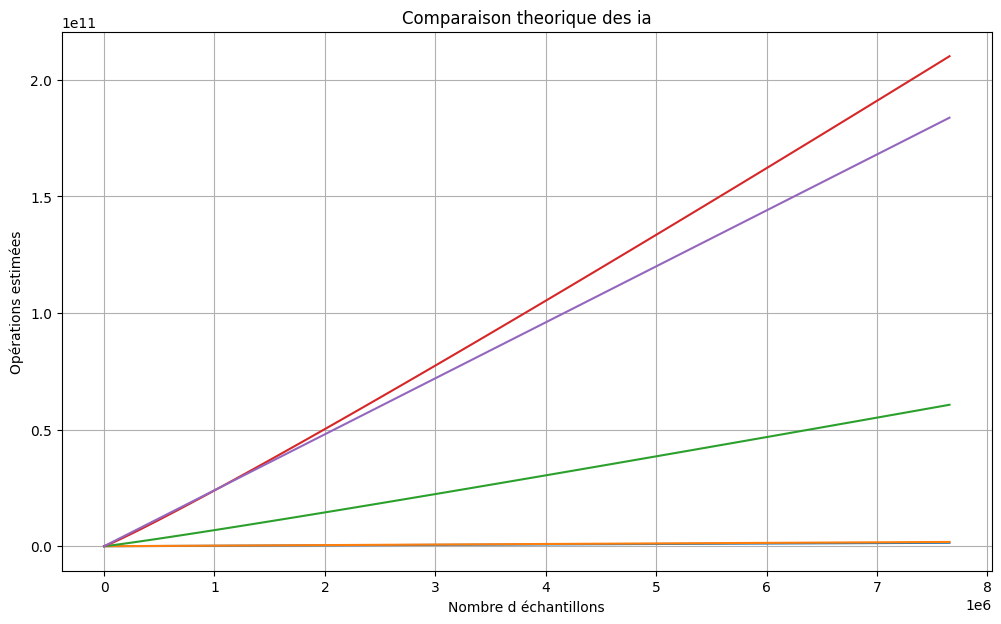

In [72]:
# 1. Configuration de la simulation
# On fait varier N (nombre d'échantillons) de 1 000 à 50 000
N = np.linspace(1, 7656670, 100)

# Constantes fixées (
d = 12            # Nombre de features (colonnes)
K = 100           # Nombre d'arbres (pour RF, XGB, LGBM)
I = 20           # Nombre d'itérations (LogReg, NN)
W_nn = d * 100    # Poids du Neural Network


# Logistic regression= O(I*N*d)
y_logreg = I * N * d

# Random forest = O(K*N*log(N)*sqrt(d) )
y_rf = K * N * np.log2(N) * np.sqrt(d)

# xgboost = O(K*N*log(N)*d)
y_xgb = K * N * np.log2(N) * d

# Lightgbm= O(K * N_sample * d_bundle)
y_lgbm = K * (N * 0.2) * (d * 0.8)

# Neural network = O(I*N*W)
y_nn = I * N * W_nn


plt.figure(figsize=(12, 7))

# Tracer des courbes
plt.plot(N, y_lgbm, label='LightGBM')
plt.plot(N, y_logreg, label='Logistic Regression')
plt.plot(N, y_rf, label='Random Forest')
plt.plot(N, y_xgb, label='XGBoost')
plt.plot(N, y_nn, label='Neural Network')

# Label
plt.title('Comparaison theorique des ia')
plt.xlabel('Nombre d échantillons')
plt.ylabel('Opérations estimées')
plt.grid(True)

# Affichage
plt.show()

In [73]:
def init_lightgbm(n_estimators=500, learning_rate=0.1):
    model = lgb.LGBMClassifier(
        n_estimators = n_estimators,
        learning_rate = learning_rate,
        verbose=-1
    )
    return model

In [74]:
light = init_lightgbm()
light.fit(input_train, output_train)

,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,500
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [75]:
output_pred = light.predict(input_test)

print(f"Accuracy : {accuracy_score(output_test, output_pred):.2%}")

Accuracy : 100.00%
